# Revision history

Track every published change to the August 2008 PAYEMS observation, then run the same point-in-time check across several economic series. Values are shown in each series' native units.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import find_dotenv, load_dotenv
from IPython.display import display

from asof import get_revision_history

load_dotenv(find_dotenv())
API_KEY = os.getenv("FRED_API_KEY")
assert API_KEY, "FRED_API_KEY was not loaded from .env"

In [2]:
payems = get_revision_history(
    series_id="PAYEMS",
    observation_date="2008-08-01",
    api_key=API_KEY,
)

payems_revisions = pd.DataFrame(
    [
        {"vintage_date": revision.vintage_date, "value_thousands": revision.value}
        for revision in payems.revisions
    ]
)
payems_revisions["change_from_prior_thousands"] = payems_revisions["value_thousands"].diff()
payems_revisions["change_from_initial_thousands"] = (
    payems_revisions["value_thousands"] - payems.initial.value
)
display(payems_revisions.style.format(precision=1, thousands=",", na_rep="—"))

,vintage_date,value_thousands,change_from_prior_thousands,change_from_initial_thousands
0,2008-09-05,"137,473.0",—,0.0
1,2008-10-03,"137,477.0",4.0,4.0
2,2008-11-07,"137,423.0",-54.0,-50.0
3,2009-02-06,"137,053.0",-370.0,-420.0
4,2010-02-05,"136,741.0",-312.0,-732.0
5,2011-02-04,"136,747.0",6.0,-726.0
6,2012-02-03,"136,764.0",17.0,-709.0
7,2013-02-01,"136,836.0",72.0,-637.0
8,2014-02-07,"137,162.0",326.0,-311.0
9,2016-02-05,"137,233.0",71.0,-240.0


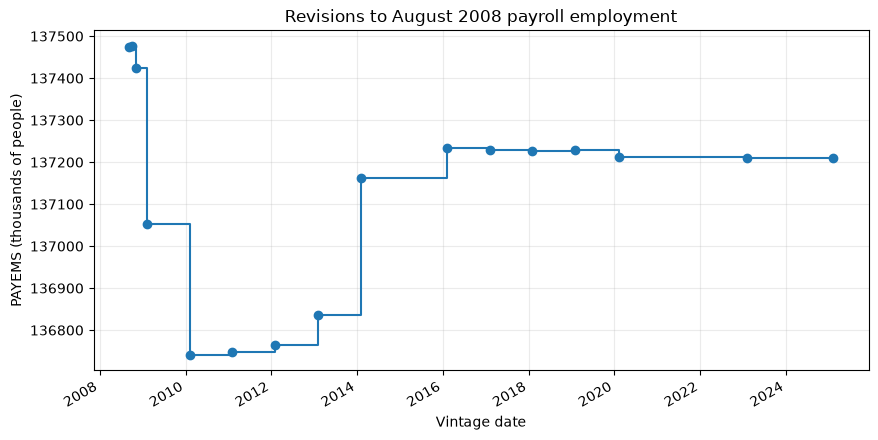

In [3]:
plot_data = payems_revisions.assign(
    vintage_date=pd.to_datetime(payems_revisions["vintage_date"])
)
fig, ax = plt.subplots(figsize=(10, 5))
ax.step(
    plot_data["vintage_date"],
    plot_data["value_thousands"],
    where="post",
    marker="o",
)
ax.set(
    title="Revisions to August 2008 payroll employment",
    xlabel="Vintage date",
    ylabel="PAYEMS (thousands of people)",
)
ax.grid(alpha=0.25)
fig.autofmt_xdate()
plt.show()

## Cross-series check

Revision patterns differ by source and series. The figures below remain in native units, so their magnitudes should not be compared directly. In particular, GDP history can move substantially after comprehensive revisions and changes to the reference year.

In [4]:
cases = {
    "PAYEMS": "2008-08-01",
    "UNRATE": "2008-08-01",
    "CPIAUCSL": "2008-08-01",
    "GDPC1": "2008-07-01",
    "FEDFUNDS": "2008-08-01",
}

histories = {
    series_id: get_revision_history(
        series_id=series_id,
        observation_date=observation_date,
        api_key=API_KEY,
    )
    for series_id, observation_date in cases.items()
}

validation = pd.DataFrame(
    [
        {
            "series_id": history.series_id,
            "observation_date": history.observation_date,
            "published_values": len(history.revisions),
            "initial_vintage": history.initial.vintage_date,
            "initial_value": history.initial.value,
            "latest_change": history.current.vintage_date,
            "latest_value": history.current.value,
            "total_revision": history.total_revision,
        }
        for history in histories.values()
    ]
)
display(validation.style.format(precision=3, thousands=","))

,series_id,observation_date,published_values,initial_vintage,initial_value,latest_change,latest_value,total_revision
0,PAYEMS,2008-08-01,16,2008-09-05,"137,473.000",2025-02-07,"137,211.000",-262.000
1,UNRATE,2008-08-01,3,2008-09-05,6.100,2010-01-08,6.100,0.000
2,CPIAUCSL,2008-08-01,6,2008-09-16,218.880,2013-02-19,218.690,-0.190
3,GDPC1,2008-07-01,12,2008-10-30,"11,720.000",2023-09-28,"16,854.295","5,134.295"
4,FEDFUNDS,2008-08-01,1,2008-09-02,2.000,2008-09-02,2.000,0.000
